In [1]:
!pip install kaggle

In [2]:
!pip install kagglehub   

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("d4rklucif3r/cat-and-dogs")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ARTH\.cache\kagglehub\datasets\d4rklucif3r\cat-and-dogs\versions\1


In [4]:
# reading files

In [5]:
import os

path = '/dataset/training_set'

if os.path.exists(path):
    dirs, subdirs, files = next(os.walk(path))
    file_count = len(files)
    print('Number of Images:', file_count)
else:
    print("Dataset path does not exist!")

Dataset path does not exist!


In [6]:
path = os.path.join(os.getcwd(), 'dataset', 'training_set')

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    if os.path.isdir(folder_path):
        images = os.listdir(folder_path)
        print(f'{folder}: {len(images)} images')

cats: 4000 images
dogs: 4000 images
resized_images: 2 images


In [7]:
# printing all the images name

In [8]:
file_names = os.listdir('dataset/training_set')

In [9]:
file_names

['cats', 'dogs', 'resized_images']

In [10]:
# importing Dependencies

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
from sklearn.model_selection import train_test_split

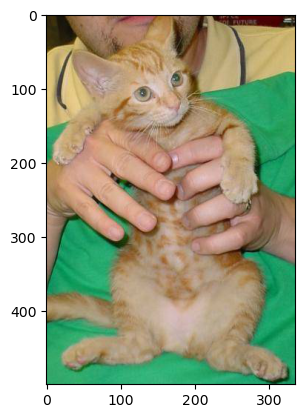

In [12]:
img = mpimg.imread('dataset/training_set/cats/cat.1001.jpg')
imgplt = plt.imshow(img)
plt.show()

In [13]:
# Resizing the images for model training

In [14]:
os.mkdir('dataset/training_set/resized_images')

FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'dataset/training_set/resized_images'

In [ ]:
# Source and destination paths
source_path = 'dataset/training_set'
destination_path = 'dataset/training_set/resized_images'

# Create folders for resized images
os.makedirs(os.path.join(destination_path, 'cats'), exist_ok=True)
os.makedirs(os.path.join(destination_path, 'dogs'), exist_ok=True)

# Resize images
for category in ['cats', 'dogs']:
    folder_path = os.path.join(source_path, category)
    save_path = os.path.join(destination_path, category)

    for file_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file_name)

        try:
            with Image.open(image_path) as img:
                img = img.convert('RGB')
                img = img.resize((224, 224))
                img.save(os.path.join(save_path, file_name))

        except Exception as e:
            print(f"Skipping {file_name}: {e}")

    print(f"{category} images resized successfully!")

print("All images resized to 224 × 224.")

In [ ]:
# Resized images

img = mpimg.imread('dataset/training_set/resized_images/dogs/dog.1001.jpg')
imgplt = plt.imshow(img)
plt.show()

In [ ]:
# Creating lables to images
# Cats -- 0
# Dogs -- 1

In [ ]:
data = []

# Cats = 0
for file_name in os.listdir('dataset/training_set/resized_images/cats'):
    image_path = os.path.join(
        'dataset/training_set/resized_images/cats',
        file_name
    )
    data.append([image_path, 0])

# Dogs = 1
for file_name in os.listdir('dataset/training_set/resized_images/dogs'):
    image_path = os.path.join(
        'dataset/training_set/resized_images/dogs',
        file_name
    )
    data.append([image_path, 1])

In [ ]:
#Model Training

In [15]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models

train_path = 'dataset/training_set/resized_images'

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode='binary',
    validation_split=0.2,
    subset='training',
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode='binary',
    validation_split=0.2,
    subset='validation',
    seed=42
)

print(train_ds.class_names)

Found 8000 files belonging to 2 classes.
Using 6400 files for training.
Found 8000 files belonging to 2 classes.
Using 1600 files for validation.
['cats', 'dogs']


In [18]:
#Model training

In [19]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

In [20]:
#Compile Model

In [21]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
#Model Training

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\ARTH\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


200/200 ━━━━━━━━━━━━━━━━━━━━ 171s 847ms/step - accuracy: 0.5437 - loss: 0.6910 - val_accuracy: 0.6356 - val_loss: 0.6472
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 157s 786ms/step - accuracy: 0.6408 - loss: 0.6376 - val_accuracy: 0.6988 - val_loss: 0.5563
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 163s 817ms/step - accuracy: 0.7036 - loss: 0.5812 - val_accuracy: 0.7038 - val_loss: 0.5401
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 162s 811ms/step - accuracy: 0.7503 - loss: 0.5065 - val_accuracy: 0.7094 - val_loss: 0.5734
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 152s 761ms/step - accuracy: 0.7978 - loss: 0.4325 - val_accuracy: 0.7175 - val_loss: 0.5743
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 155s 776ms/step - accuracy: 0.8392 - loss: 0.3605 - val_accuracy: 0.7531 - val_loss: 0.5643
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 159s 796ms/step - accuracy: 0.8739 - loss: 0.2971 - val_accuracy: 0.7625 - val_loss: 0.5841
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 164s 819ms/step - accuracy: 0.9116 - loss: 0.22

In [24]:
#Best Epoch value for batter accutracy

best_loss_epoch = np.argmin(history.history['val_loss']) + 1
best_accuracy_epoch = np.argmax(history.history['val_accuracy']) + 1

print("Best epoch based on validation loss:", best_loss_epoch)
print("Lowest validation loss:", min(history.history['val_loss']))

print("Best epoch based on validation accuracy:", best_accuracy_epoch)
print("Highest validation accuracy:", max(history.history['val_accuracy']))

Best epoch based on validation loss: 3
Lowest validation loss: 0.5401110649108887
Best epoch based on validation accuracy: 8
Highest validation accuracy: 0.7649999856948853


In [25]:
#Saved Trained Model

model.save('cat_dog_model.keras')

In [26]:
model = tf.keras.models.load_model('cat_dog_model.keras')

In [28]:
#Predict new image

img = Image.open(
    'dataset/single_prediction/cat_or_dog_2.jpg'
).convert('RGB')

img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)[0][0]

if prediction >= 0.5:
    print("Dog")
else:
    print("Cat")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Cat
